# Assignment 3 — Task 1: Rebuild and diagnose nine charts

This notebook rebuilds each published chart from the recipe in `TASKS.md`, checks its self-check value, records the tempting decoy explanation, and plots an honest redesign. The data is synthetic and lives in `data/`.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, linregress

from vizlib import PALETTE, style_defaults, save_fig

ROOT = Path(".")
DATA = ROOT / "data"
style_defaults()
sns.set_theme(style="whitegrid")

## Case 1 — helmet grade and head-injury rate

The published recipe aggregates injuries and trips before calculating injuries per 1,000 trips. The honest redesign adds exposure directly to the label and avoids implying that certification alone caused the difference.

,head_injuries,trips,injuries_per_1000
helmet_grade,,,
Standard,129,60000,2.15
Premium,216,40000,5.40


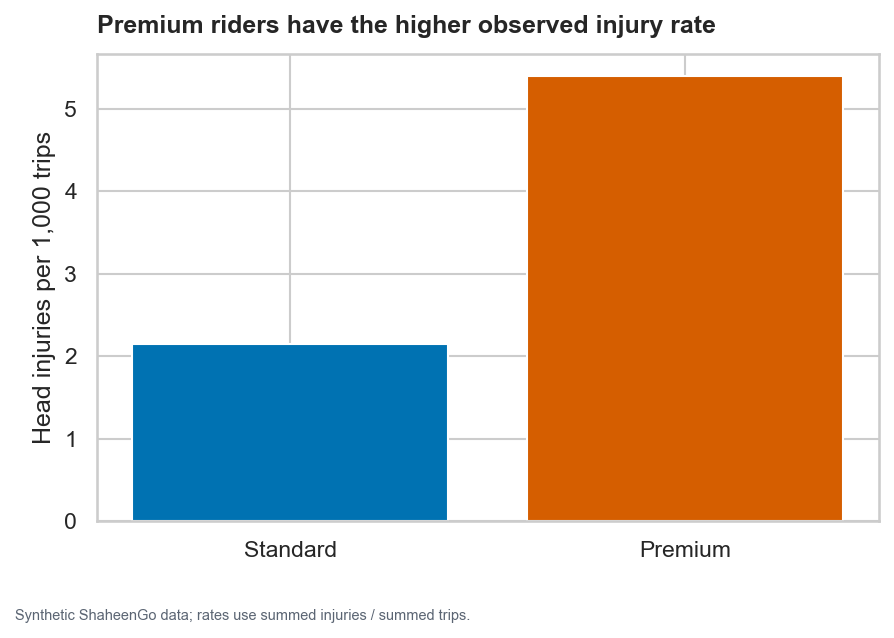

In [17]:
helmet = pd.read_csv(DATA / "case01_helmet_rickshaw.csv")
helmet_summary = helmet.groupby("helmet_grade", sort=False)[["head_injuries", "trips"]].sum()
helmet_summary["injuries_per_1000"] = helmet_summary["head_injuries"] / helmet_summary["trips"] * 1000
display(helmet_summary)
assert np.isclose(helmet_summary.loc["Standard", "injuries_per_1000"], 2.15, atol=.01)
assert np.isclose(helmet_summary.loc["Premium", "injuries_per_1000"], 5.40, atol=.01)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(helmet_summary.index, helmet_summary["injuries_per_1000"], color=PALETTE["series"][:2])
ax.set(title="Premium riders have the higher observed injury rate", ylabel="Head injuries per 1,000 trips")
ax.set_ylim(0, None)
fig.tight_layout()
save_fig(fig, "task1_case1_honest.png", "Synthetic ShaheenGo data; rates use summed injuries / summed trips.")
plt.show()

**Diagnosis:** The chart invites “premium helmets cause more injuries.” The decoy is certification quality; the rider-level exposure columns must be checked instead. The mechanism to test is confounding by rider behaviour and road mix, not generic causation language.

In [18]:
display(helmet.groupby(["helmet_grade", "road_type"])[["head_injuries", "trips"]].sum())
display(helmet.groupby("helmet_grade")[["avg_speed_kph", "months_experience"]].mean())

head_injuries  trips
helmet_grade road_type                             
Premium      City arterial                11   5000
             Inner-city lanes              1   1000
             Motorway                    204  34000
Standard     City arterial                60  20000
             Inner-city lanes             53  38000
             Motorway                     16   2000

,avg_speed_kph,months_experience
helmet_grade,,
Premium,66.953250,31.422500
Standard,30.223833,31.498333


## Case 2 — chai sales and quiz failures

Pearson r = 0.98


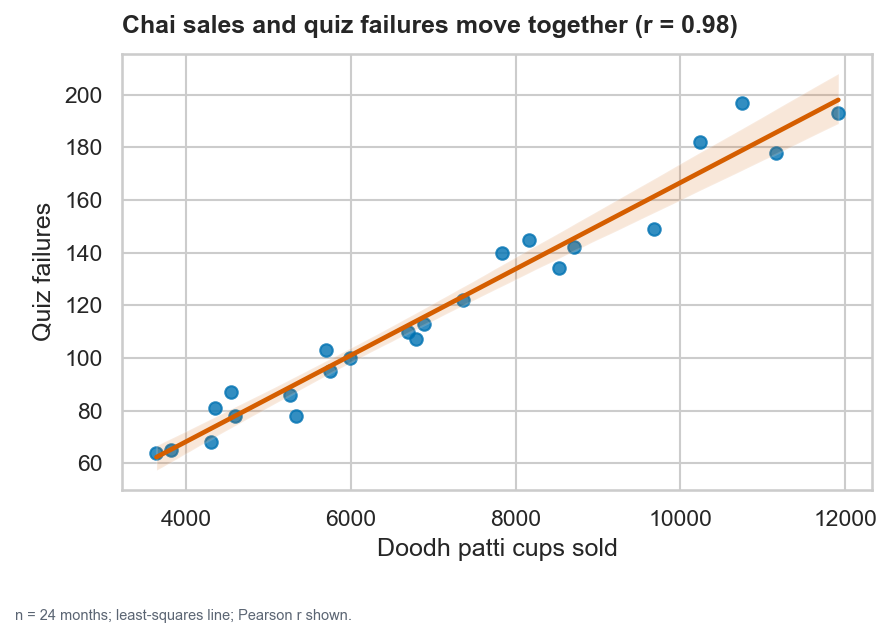

In [19]:
chai = pd.read_csv(DATA / "case02_chai_quizzes.csv")
r = chai["cups_doodh_patti_sold"].corr(chai["quiz_failures"])
slope, intercept, *_ = linregress(chai["cups_doodh_patti_sold"], chai["quiz_failures"])
print(f"Pearson r = {r:.2f}")
assert np.isclose(r, .98, atol=.01)

fig, ax = plt.subplots(figsize=(6, 4))
sns.regplot(data=chai, x="cups_doodh_patti_sold", y="quiz_failures", ax=ax,
            scatter_kws={"color": PALETTE["series"][0]}, line_kws={"color": PALETTE["highlight"]})
ax.set(title=f"Chai sales and quiz failures move together (r = {r:.2f})",
       xlabel="Doodh patti cups sold", ylabel="Quiz failures")
fig.tight_layout()
save_fig(fig, "task1_case2_honest.png", "n = 24 months; least-squares line; Pearson r shown.")
plt.show()

**Diagnosis:** The decoy is a causal claim about chai. Check the unplotted context columns: exam months, enrolment, and open days can drive both series. A redesign should show the relevant rate or stratify by exam period rather than treat two seasonal counts as a causal relationship.

,cups_doodh_patti_sold,failures_per_100_students
is_exam_month,,
0,6902.4375,3.414557
1,7195.3750,3.861799


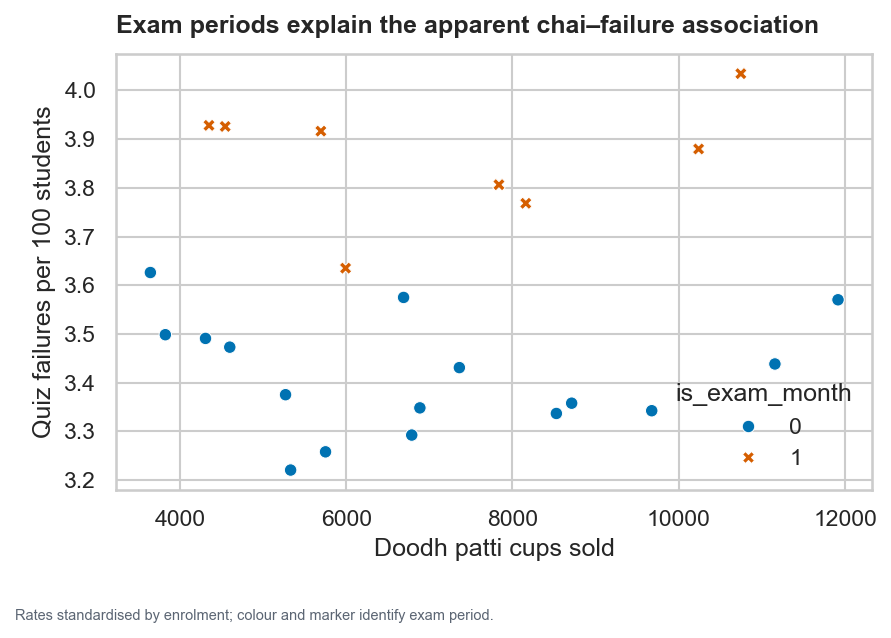

In [20]:
chai["failures_per_100_students"] = chai["quiz_failures"] / chai["students_enrolled"] * 100
display(chai.groupby("is_exam_month")[["cups_doodh_patti_sold", "failures_per_100_students"]].mean())
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=chai, x="cups_doodh_patti_sold", y="failures_per_100_students",
                hue="is_exam_month", style="is_exam_month", palette=PALETTE["series"][:2], ax=ax)
ax.set(title="Exam periods explain the apparent chai–failure association",
       xlabel="Doodh patti cups sold", ylabel="Quiz failures per 100 students")
fig.tight_layout()
save_fig(fig, "task1_case2_redesign.png", "Rates standardised by enrolment; colour and marker identify exam period.")
plt.show()

## Case 3 — AQI before and after the action plan

Before = 202, after = 137; fall = 32%


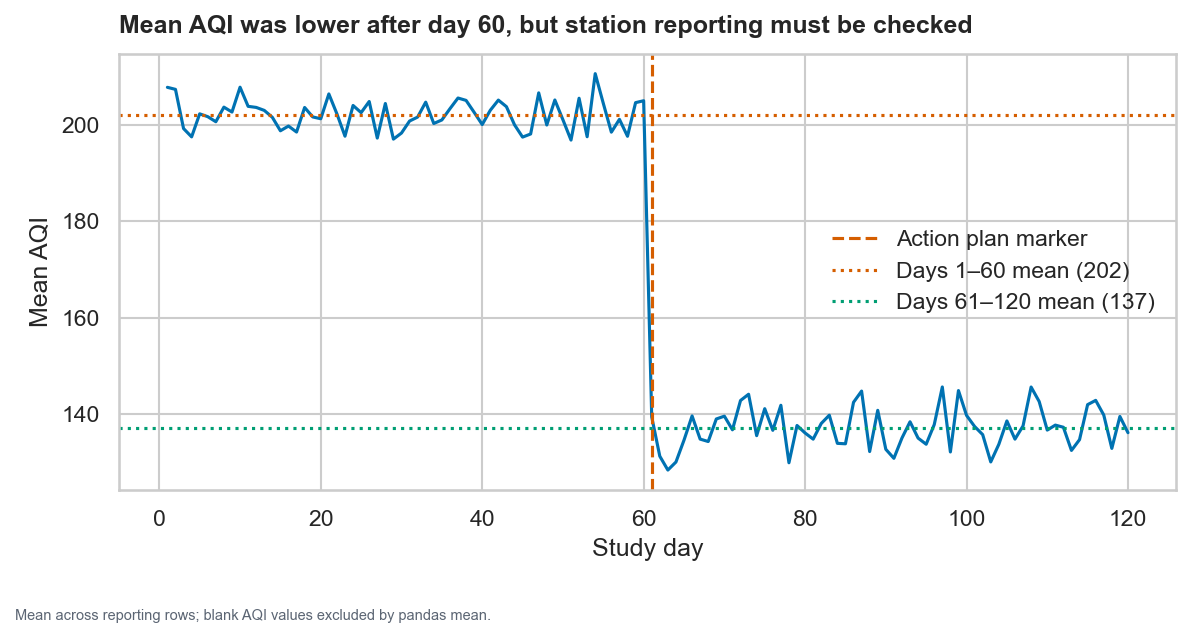

In [21]:
aqi = pd.read_csv(DATA / "case03_aqi_monitors.csv")
aqi["date"] = pd.to_datetime(aqi["date"])
daily = aqi.groupby("date", as_index=False)["aqi"].mean()
daily["day"] = np.arange(1, len(daily) + 1)
before = daily.loc[daily["day"] <= 60, "aqi"].mean()
after = daily.loc[daily["day"] > 60, "aqi"].mean()
print(f"Before = {before:.0f}, after = {after:.0f}; fall = {(1-after/before)*100:.0f}%")
assert np.isclose(before, 202, atol=1)
assert np.isclose(after, 137, atol=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(daily["day"], daily["aqi"], color=PALETTE["series"][0])
ax.axvline(61, color=PALETTE["highlight"], ls="--", label="Action plan marker")
ax.axhline(before, color=PALETTE["series"][1], ls=":", label=f"Days 1–60 mean ({before:.0f})")
ax.axhline(after, color=PALETTE["series"][2], ls=":", label=f"Days 61–120 mean ({after:.0f})")
ax.set(title="Mean AQI was lower after day 60, but station reporting must be checked",
       xlabel="Study day", ylabel="Mean AQI")
ax.legend()
fig.tight_layout()
save_fig(fig, "task1_case3_honest.png", "Mean across reporting rows; blank AQI values excluded by pandas mean.")
plt.show()

**Diagnosis:** The decoy is “the axis is truncated”; it is explicitly zero-based. The real mechanism to investigate is changing station coverage and reporting, because a blank is not a zero. Compare reporting counts and show the distribution rather than only the pooled mean.

count    120.000000
mean      17.500000
std        4.518868
min       13.000000
25%       13.000000
50%       17.500000
75%       22.000000
max       22.000000
Name: reported, dtype: float64


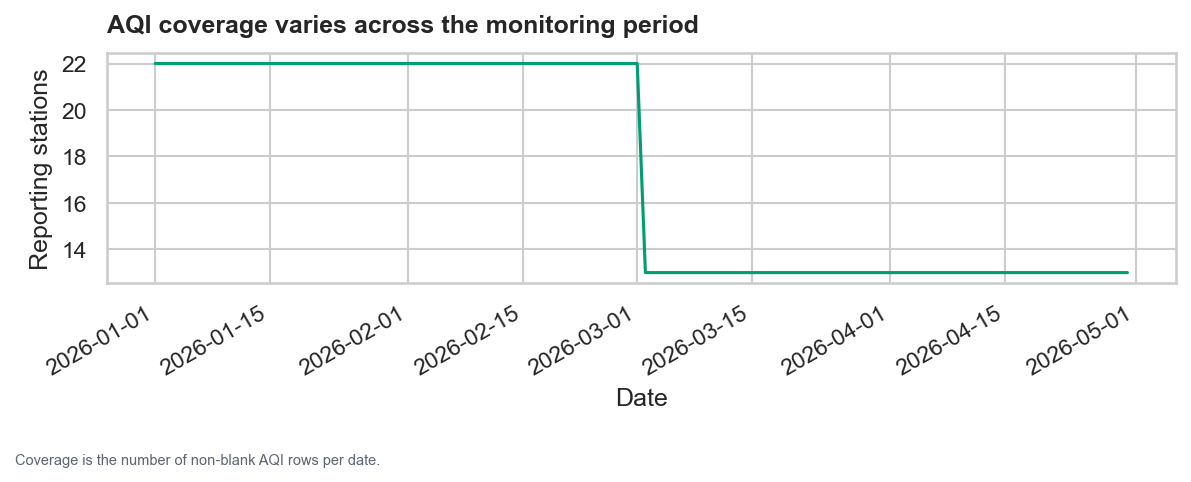

In [22]:
coverage = aqi.assign(reported=aqi["aqi"].notna()).groupby("date")["reported"].sum()
print(coverage.describe())
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(coverage.index, coverage.values, color=PALETTE["series"][2])
ax.set(title="AQI coverage varies across the monitoring period", ylabel="Reporting stations", xlabel="Date")
fig.autofmt_xdate()
fig.tight_layout()
save_fig(fig, "task1_case3_redesign.png", "Coverage is the number of non-blank AQI rows per date.")
plt.show()

## Cases 4 and 5 — identical summaries can hide different shapes

In [23]:
def summary_table(frame, group_col):
    rows = []
    for name, group in frame.groupby(group_col, sort=True):
        x = group.iloc[:, -2]
        y = group.iloc[:, -1]
        fit = linregress(x, y)
        rows.append({"group": name, "n": len(group), "mean_x": x.mean(), "mean_y": y.mean(),
                     "sd_x": x.std(ddof=0), "sd_y": y.std(ddof=0), "r": x.corr(y),
                     "slope": fit.slope})
    return pd.DataFrame(rows).set_index("group")

quartet = pd.read_csv(DATA / "case04_quartet_depts.csv")
same_stats = pd.read_csv(DATA / "case05_same_stats_shapes.csv")
display(summary_table(quartet, "department").round(3))
display(summary_table(same_stats, "shape_name").round(3))
assert np.allclose(summary_table(quartet, "department")["r"], .816, atol=.01)
assert np.allclose(summary_table(same_stats, "shape_name")["r"], .420, atol=.01)

,n,mean_x,mean_y,sd_x,sd_y,r,slope
group,,,,,,,
Architecture,11,18.0,14.501,6.325,1.936,0.817,0.25
Business Administration,11,18.0,14.501,6.325,1.937,0.816,0.25
Computer Science,11,18.0,14.501,6.325,1.937,0.816,0.25
Electrical Engineering,11,18.0,14.500,6.325,1.936,0.816,0.25


,n,mean_x,mean_y,sd_x,sd_y,r,slope
group,,,,,,,
ring,180,48.0,63.0,12.0,15.0,0.42,0.525
star,180,48.0,63.0,12.0,15.0,0.42,0.525
straight line,180,48.0,63.0,12.0,15.0,0.42,0.525
the letter X,180,48.0,63.0,12.0,15.0,0.42,0.525
two clusters,180,48.0,63.0,12.0,15.0,0.42,0.525


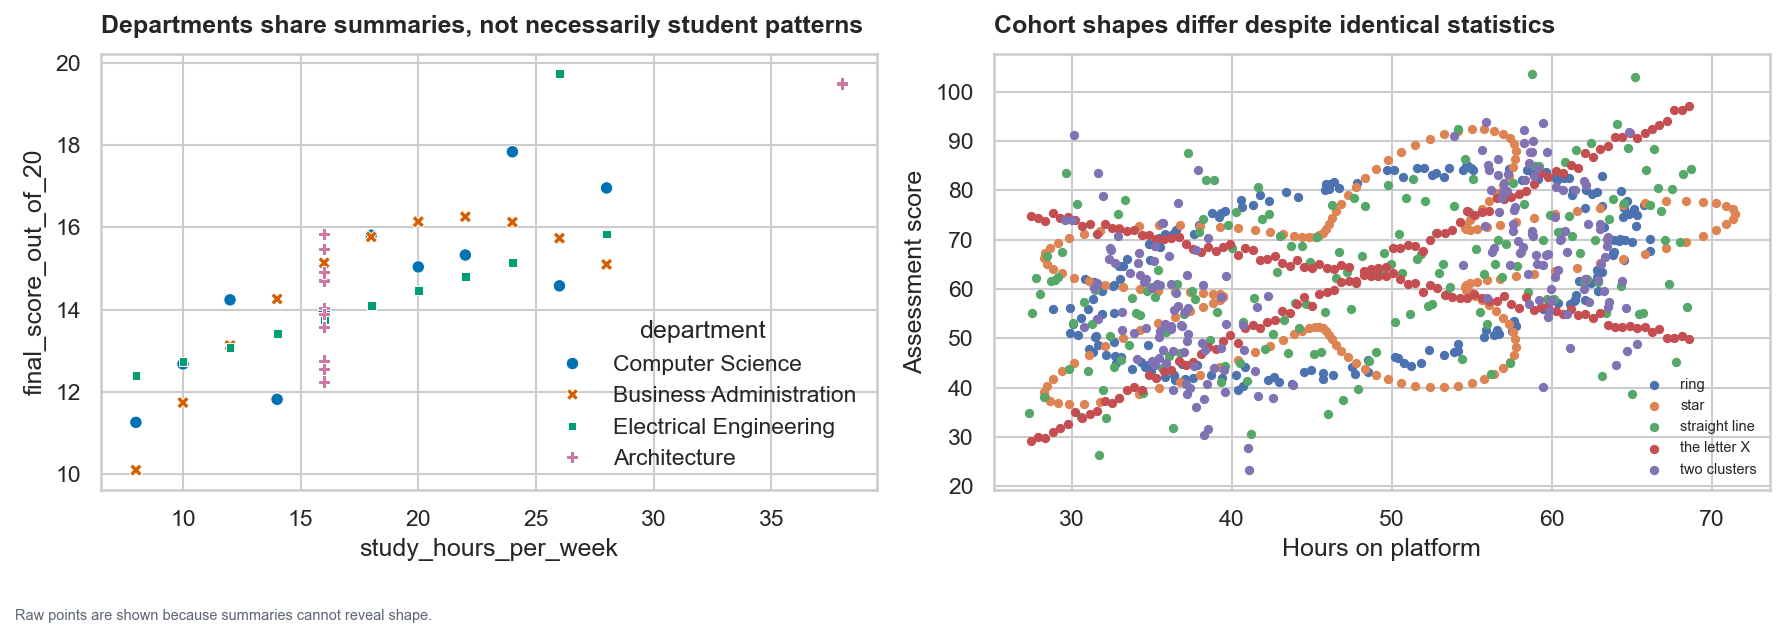

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=quartet, x="study_hours_per_week", y="final_score_out_of_20",
                hue="department", style="department", palette=PALETTE["series"] + [PALETTE["series_4th"]], ax=axes[0])
axes[0].set(title="Departments share summaries, not necessarily student patterns")
for name, group in same_stats.groupby("shape_name"):
    axes[1].scatter(group["hours_on_platform"], group["assessment_score"], s=12, label=name)
axes[1].set(title="Cohort shapes differ despite identical statistics",
            xlabel="Hours on platform", ylabel="Assessment score")
axes[1].legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "task1_cases4_5_redesign.png", "Raw points are shown because summaries cannot reveal shape.")
plt.show()

**Diagnosis:** For both cases the decoy is that equal means, SDs, and correlations imply equal behaviour. The mechanism is distributional shape, outliers, clustering, and leverage. A scatter or small-multiple plot reveals what a table cannot.

## Case 6 — correlation screening

(20, 20) creatinine vs HbA1c: 0.7651666421647184 systolic vs MAP: 0.9583647744991359


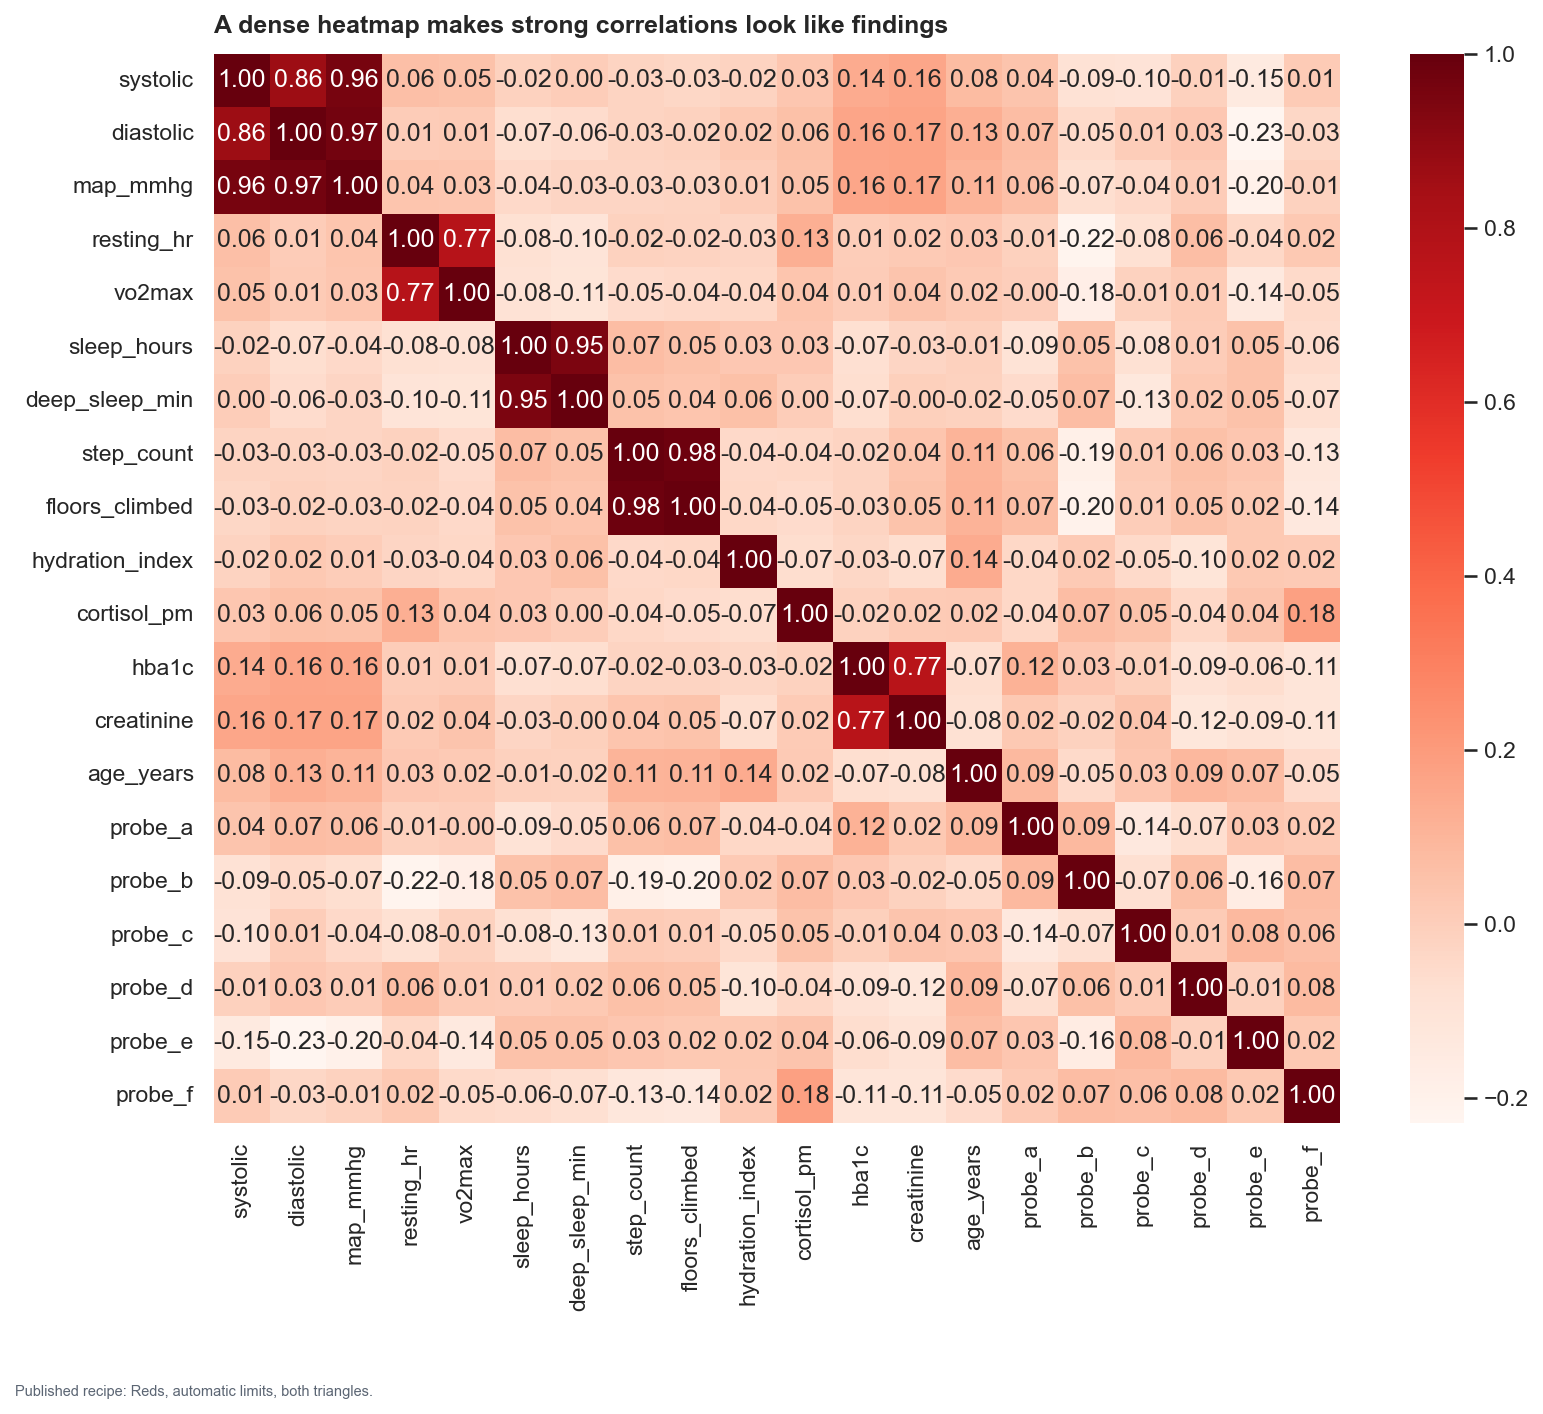

In [25]:
sensor = pd.read_csv(DATA / "case06_sensor_matrix.csv")
excluded = ["age_band", "study_site", "hr_device_model"]
numeric = sensor.select_dtypes("number").drop(columns=excluded, errors="ignore")
corr = numeric.corr()
print(corr.shape, "creatinine vs HbA1c:", corr.loc["creatinine", "hba1c"],
      "systolic vs MAP:", corr.loc["systolic", "map_mmhg"])
assert corr.shape == (20, 20)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="Reds", annot=True, fmt=".2f", ax=ax)
ax.set(title="A dense heatmap makes strong correlations look like findings")
fig.tight_layout()
save_fig(fig, "task1_case6_published.png", "Published recipe: Reds, automatic limits, both triangles.")
plt.show()

**Diagnosis:** The mechanism is not established causation: instrument design, arithmetic derivation (MAP), and multiple comparisons can create apparent relationships. The drawing problem is a sequential map with automatic limits and duplicated triangles; it hides sign and makes comparison harder. A redesign masks the upper triangle and uses a diverging scale fixed at −1 to +1.

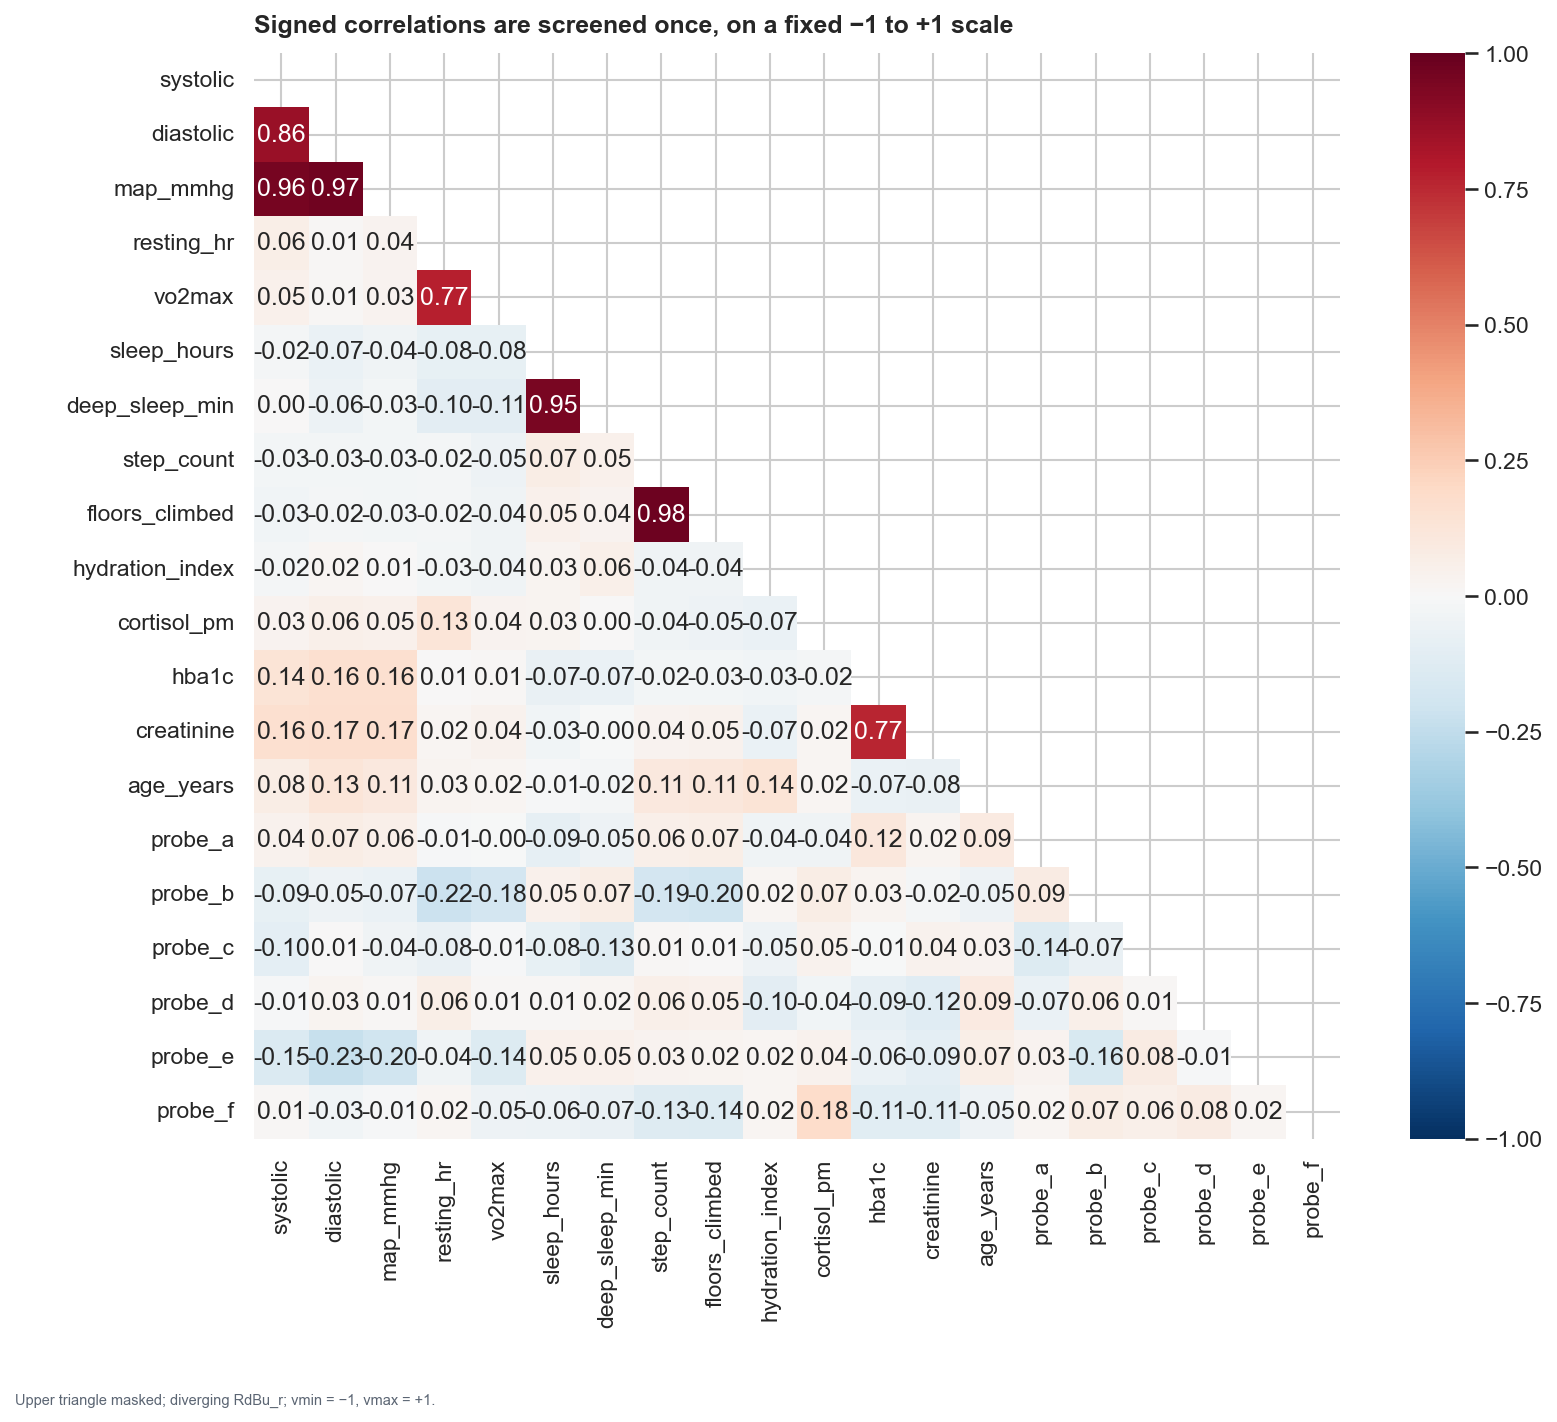

In [26]:
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap=PALETTE["diverging"], vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", ax=ax, square=True)
ax.set(title="Signed correlations are screened once, on a fixed −1 to +1 scale")
fig.tight_layout()
save_fig(fig, "task1_case6_redesign.png", "Upper triangle masked; diverging RdBu_r; vmin = −1, vmax = +1.")
plt.show()

## Case 7 — dual-axis revenue and cost

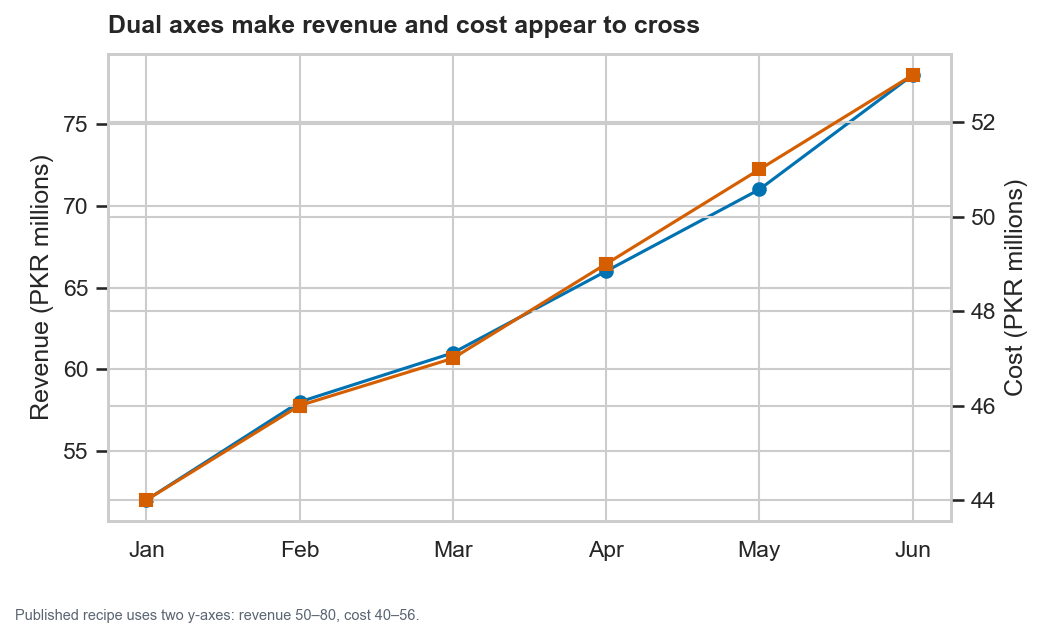

First four months: cost line is visually above revenue under the published scales.


In [27]:
series = pd.read_csv(DATA / "case07_dual_axis_series.csv")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(series["month"], series["revenue_pkr_m"], marker="o", label="Revenue", color=PALETTE["series"][0])
ax2 = ax.twinx()
ax2.plot(series["month"], series["cost_pkr_m"], marker="s", label="Cost", color=PALETTE["highlight"])
ax.set(title="Dual axes make revenue and cost appear to cross", ylabel="Revenue (PKR millions)")
ax2.set_ylabel("Cost (PKR millions)")
fig.tight_layout()
save_fig(fig, "task1_case7_published.png", "Published recipe uses two y-axes: revenue 50–80, cost 40–56.")
plt.show()
print("First four months: cost line is visually above revenue under the published scales.")

**Diagnosis:** A Lie Factor cannot be computed for a dual-axis comparison because there is no single common ink baseline or shared scale. Both measures are already in PKR millions, so the honest redesign uses one axis and shows the actual margin.

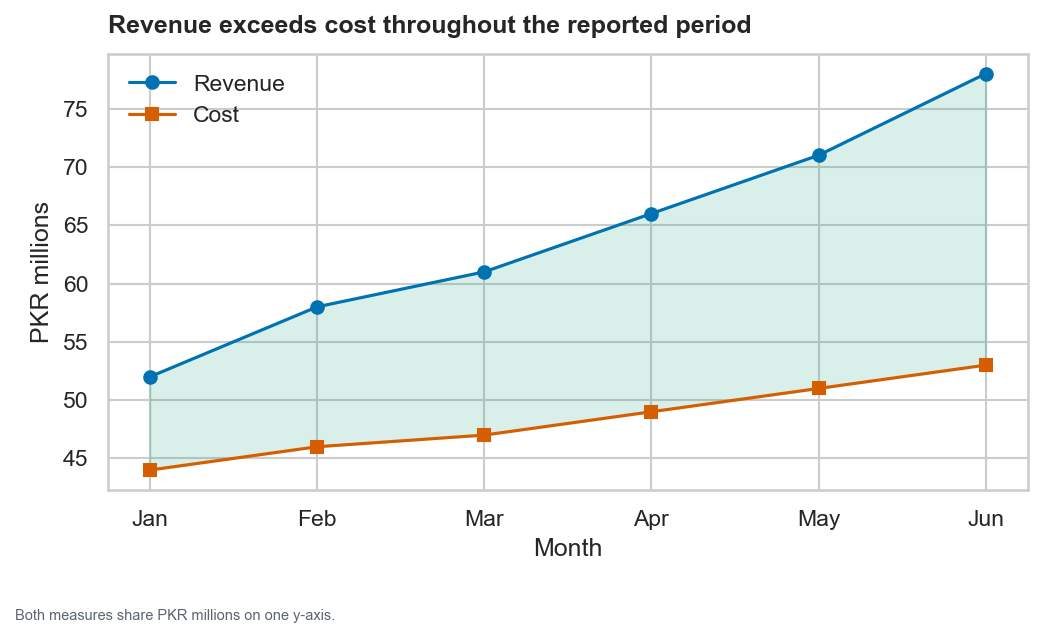

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(series["month"], series["revenue_pkr_m"], marker="o", label="Revenue", color=PALETTE["series"][0])
ax.plot(series["month"], series["cost_pkr_m"], marker="s", label="Cost", color=PALETTE["highlight"])
ax.fill_between(series["month"], series["cost_pkr_m"], series["revenue_pkr_m"],
                where=series["revenue_pkr_m"].to_numpy() >= series["cost_pkr_m"].to_numpy(),
                color=PALETTE["series"][2], alpha=.15)
ax.set(title="Revenue exceeds cost throughout the reported period",
       ylabel="PKR millions", xlabel="Month")
ax.legend()
fig.tight_layout()
save_fig(fig, "task1_case7_redesign.png", "Both measures share PKR millions on one y-axis.")
plt.show()

## Cases 8 and 9 — binning and KDE are choices

The three histograms deliberately use different bin counts. The density estimate deliberately extends beyond a physical ceiling. Neither reveals new observations; both reveal a different smoothing or binning choice.

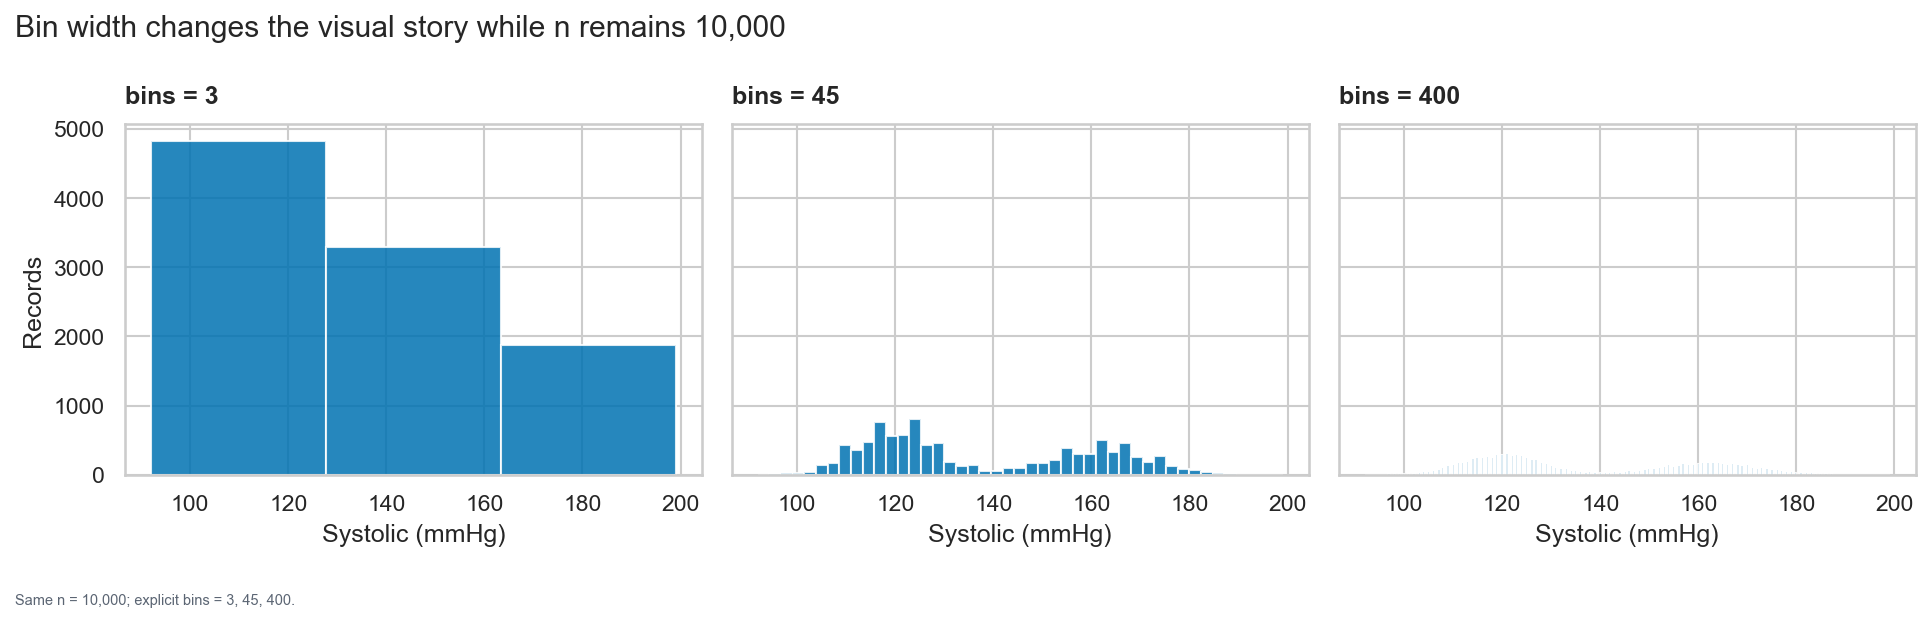

C:\Users\talha\AppData\Local\Temp\ipykernel_48696\840339005.py:19: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()
c:\Development\Fall 2026\Data-Visualization\assignment 3\vizlib.py:105: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(path, dpi=300, bbox_inches="tight",
c:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


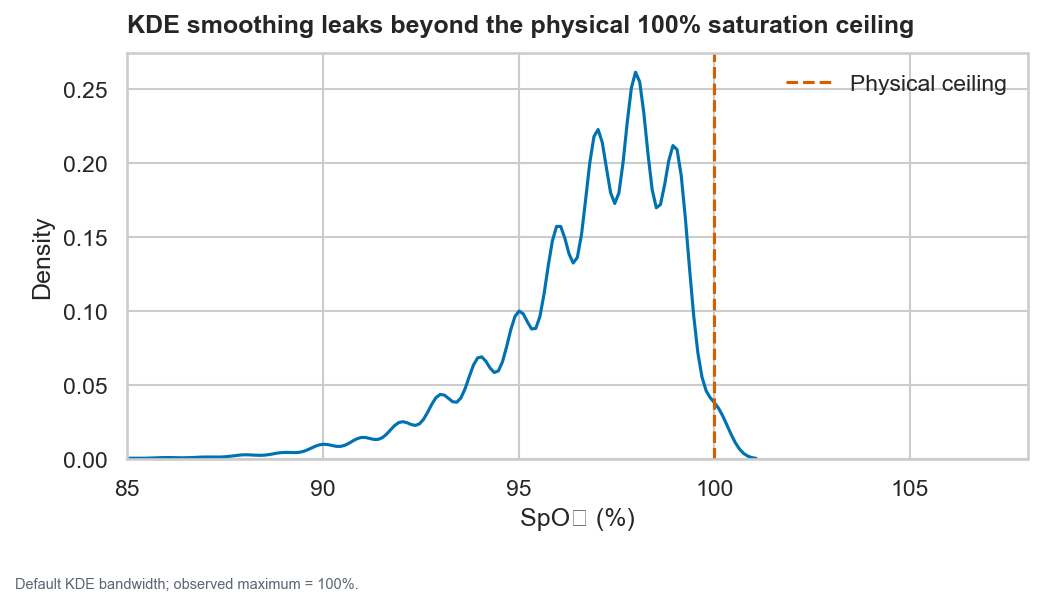

Observed maximum SpO2: 100


In [29]:
vitals = pd.read_csv(DATA / "vitals_10k.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, bins in zip(axes, [3, 45, 400]):
    ax.hist(vitals["systolic"], bins=bins, color=PALETTE["series"][0], alpha=.85)
    ax.set(title=f"bins = {bins}", xlabel="Systolic (mmHg)")
axes[0].set_ylabel("Records")
fig.suptitle("Bin width changes the visual story while n remains 10,000", x=.01, ha="left")
fig.tight_layout()
save_fig(fig, "task1_case8_bins.png", "Same n = 10,000; explicit bins = 3, 45, 400.")
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.kdeplot(data=vitals, x="spo2", ax=ax, color=PALETTE["series"][0])
ax.axvline(100, color=PALETTE["highlight"], ls="--", label="Physical ceiling")
ax.set_xlim(85, 108)
ax.set(title="KDE smoothing leaks beyond the physical 100% saturation ceiling",
       xlabel="SpO₂ (%)", ylabel="Density")
ax.legend()
fig.tight_layout()
save_fig(fig, "task1_case9_kde.png", "Default KDE bandwidth; observed maximum = 100%.")
plt.show()
print("Observed maximum SpO2:", vitals["spo2"].max())
assert vitals["spo2"].max() == 100

**Diagnosis:** The decoy for Case 8 is that one binning choice is “the distribution”; the mechanism is resolution selection. The decoy for Case 9 is that observations exceed 100%; they do not. The mechanism is KDE boundary leakage. For bounded measurements, show the empirical distribution and declare the bandwidth or use a boundary-aware method.

C:\Users\talha\AppData\Local\Temp\ipykernel_48696\3722119984.py:6: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout()


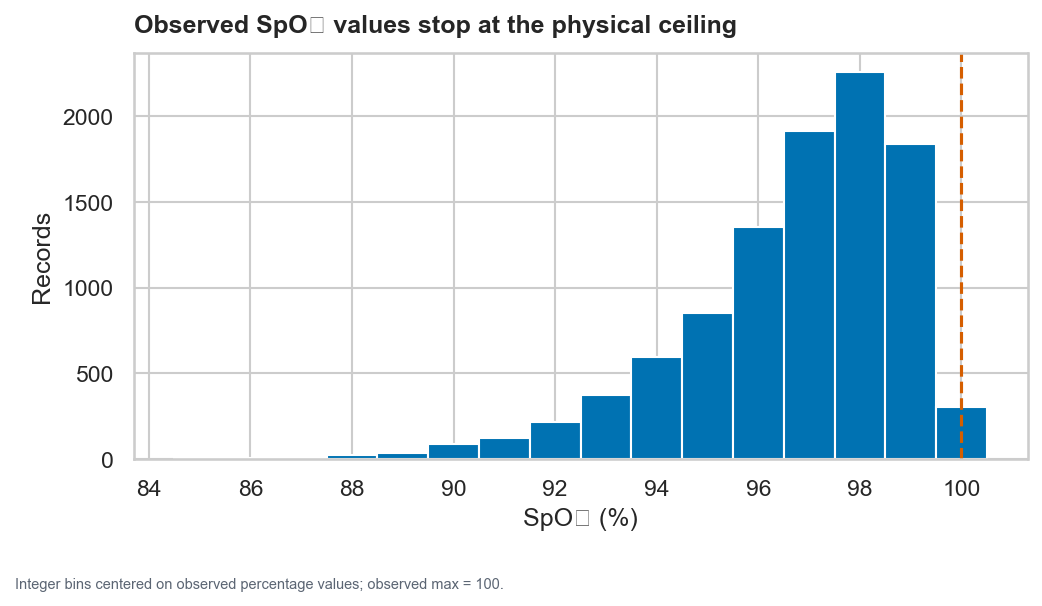

In [30]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(vitals["spo2"], bins=np.arange(84.5, 101.5, 1), color=PALETTE["series"][0])
ax.axvline(100, color=PALETTE["highlight"], ls="--")
ax.set(title="Observed SpO₂ values stop at the physical ceiling",
       xlabel="SpO₂ (%)", ylabel="Records")
fig.tight_layout()
save_fig(fig, "task1_case9_redesign.png", "Integer bins centered on observed percentage values; observed max = 100.")
plt.show()

### Submission checklist

- Every case has a rebuild, a self-check, a diagnosis, and a plotted redesign.
- The decoy explanation is separated from the mechanism.
- Parameters that change the picture are explicit.
- Figures are saved before they are shown and include source notes.